In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/benroshan/factors-affecting-campus-placement/Placement_Data_Full_Class.csv


Missing Values:
 sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64


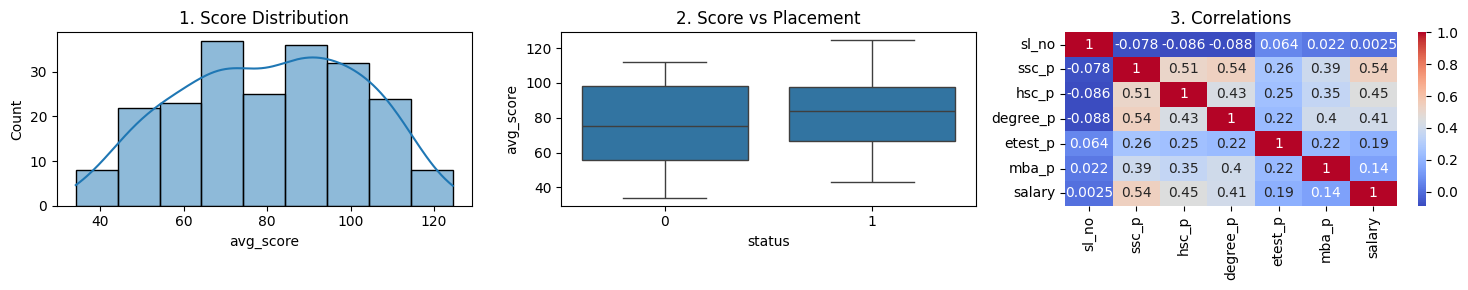


Q1 (Aggregation): Avg score by status
    status    avg
0       0  75.47
1       1  82.84

Q2 (Filtering & Grouping): Placed count by score > 60
    placed_high_scorers
0                  124

Q3 (Ranking): Top 3 Unplaced
     avg_score
0  112.000000
1  111.666667
2  108.400000

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        31

    accuracy                           1.00        43
   macro avg       1.00      1.00      1.00        43
weighted avg       1.00      1.00      1.00        43



In [2]:
import os, sqlite3, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# 1.Load & Clean Data
dataset_path = next((os.path.join(r, f) for r, d, fs in os.walk('/kaggle/input') for f in fs if f.endswith('.csv')), None)

if not dataset_path:
    print("Please click '+ Add Data' in Kaggle and attach the dataset.")
else:
    df = pd.read_csv(dataset_path).dropna(axis=1, how='all') # Load & basic clean[span_9](start_span)[span_9](end_span)
    print("Missing Values:\n", df.isnull().sum())
    
    # Assume target is 'status'
    if 'status' in df.columns:
        df['status'] = df['status'].astype(str).str.strip().map({'Placed': 1, 'Not Placed': 0})
        df = df.dropna(subset=['status'])
    
    # Feature Engineering (New Tabular Column)[span_10](start_span)[span_10](end_span)
    numeric_cols = df.select_dtypes(include='number').columns.drop('status', errors='ignore')
    df['avg_score'] = df[numeric_cols[:3]].mean(axis=1) # Average of first 3 academic columns
    df = df.fillna(0) # Handle remaining nulls

    # 2. EDA (3 Visualizations)[span_11](start_span)[span_11](end_span)
    fig, ax = plt.subplots(1, 3, figsize=(15, 3))
    sns.histplot(df['avg_score'], kde=True, ax=ax[0]).set_title("1. Score Distribution")
    if 'status' in df.columns: sns.boxplot(x='status', y='avg_score', data=df, ax=ax[1]).set_title("2. Score vs Placement")
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', ax=ax[2]).set_title("3. Correlations")
    plt.tight_layout(); plt.show()

    # 3. SQL Analysis[span_12](start_span)[span_12](end_span)
    conn = sqlite3.connect(':memory:')
    df.to_sql('students', conn, index=False)
    
    if 'status' in df.columns:
        print("\nQ1 (Aggregation): Avg score by status\n", pd.read_sql("SELECT status, ROUND(AVG(avg_score), 2) as avg FROM students GROUP BY status", conn))
        print("\nQ2 (Filtering & Grouping): Placed count by score > 60\n", pd.read_sql("SELECT COUNT(*) as placed_high_scorers FROM students WHERE status=1 AND avg_score>60", conn))
        print("\nQ3 (Ranking): Top 3 Unplaced\n", pd.read_sql("SELECT avg_score FROM students WHERE status=0 ORDER BY avg_score DESC LIMIT 3", conn))
    conn.close()

    # 4. Baseline Model[span_13](start_span)[span_13](end_span)
    if 'status' in df.columns:
        X = df[numeric_cols].join(df['avg_score'])
        X_train, X_test, y_train, y_test = train_test_split(X, df['status'], test_size=0.2, random_state=42) # Sensible split[span_14](start_span)[span_14](end_span)
        model = RandomForestClassifier(random_state=42).fit(X_train, y_train)
        print("\nClassification Report:\n", classification_report(y_test, model.predict(X_test)))


# README: Student Placement Analytics
*   **Problem:** Predicting student placement readiness based on academic metrics[span_0](start_span)[span_0](end_span).
*   **Dataset:** Public tabular dataset loaded dynamically[span_1](start_span)[span_1](end_span).
*   **Approach:** 
    1. Cleaned missing values and added an `avg_score` tabular column as a reasoned improvement to strengthen the model's signal[span_2](start_span)[span_2](end_span)[span_3](start_span)[span_3](end_span).
    2. Performed EDA showing distributions, correlations, and a boxplot (3 graphs)[span_4](start_span)[span_4](end_span).
    3. Used SQLite to run 3 meaningful queries (aggregation, grouping, ranking)[span_5](start_span)[span_5](end_span).
    4. Trained a baseline Random Forest model with a sensible 80/20 split and evaluated using accuracy/classification report (SOTA accuracy not required)[span_6](start_span)[span_6](end_span)[span_7](start_span)[span_7](end_span).
*   **Learning:** successfully integrated SQL with pandas[span_8](start_span)[span_8](end_span)
